
<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}
.markdown-content pre, .markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>
<div class="markdown-content">

# Decision Trees

**Decision Tree** یک الگوریتم Supervised Learning است که با استفاده از مجموعه‌ای از شرط‌ها و تقسیم‌های متوالی، تصمیم‌گیری می‌کند.

### ساختار

- **Root Node:** نقطه شروع درخت.
- **Internal Node:** گره‌های تصمیم‌گیری.
- **Leaf Node:** خروجی نهایی.
- **Branch:** مسیر بین گره‌ها.
- **Splitting:** تقسیم داده‌ها.

### Splitting Criteria

- **Gini Impurity:** اندازه‌گیری ناخالصی Node.
- **Entropy:** اندازه‌گیری عدم قطعیت Node.
- **Information Gain:** میزان کاهش Entropy پس از تقسیم.

### کنترل Overfitting

- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_leaf_nodes`

### نکات مهم

- Decision Tree برای Classification و Regression استفاده می‌شود.
- نیازی به StandardScaler ندارد.
- درخت بیش از حد پیچیده ممکن است Overfit شود.
- ساختار تصمیم‌گیری آن قابل مشاهده و تفسیر است.

### کتابخانه

`sklearn.tree.DecisionTreeClassifier`

</div>



<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}
.markdown-content pre, .markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>
<div class="markdown-content">

### تمرین عملی — مقایسه عمق Decision Tree

این تمرین به کدنویسی Python نیاز دارد.

کتابخانه موردنیاز: `scikit-learn`

از دیتاست Breast Cancer استفاده کن:

```python
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target
```

**وظایف:**

1. داده‌ها را به Train و Test تقسیم کن.
2. از `stratify=y` و `random_state=42` استفاده کن.
3. سه مدل Decision Tree با `max_depth=1`، `max_depth=3` و `max_depth=None` بساز.
4. هر سه مدل را آموزش بده.
5. Train Accuracy و Test Accuracy هر مدل را محاسبه کن.
6. نتایج را با یکدیگر مقایسه کن.
7. ساختار یکی از درخت‌ها را با `plot_tree` نمایش بده.

**سؤالات تحلیلی کد:**

- کدام مدل بیشترین Train Accuracy را دارد؟
- آیا بیشترین Train Accuracy به معنی بهترین مدل است؟
- با افزایش عمق درخت چه تغییری در عملکرد مدل مشاهده می‌کنی؟
- کدام مدل احتمالاً Overfitting بیشتری دارد؟ چرا؟

</div>



Max Depth: 1
Train Accuracy: 0.9230769230769231
Test Accuracy: 0.9210526315789473

Max Depth: 3
Train Accuracy: 0.9758241758241758
Test Accuracy: 0.9385964912280702

Max Depth: None
Train Accuracy: 1.0
Test Accuracy: 0.9122807017543859


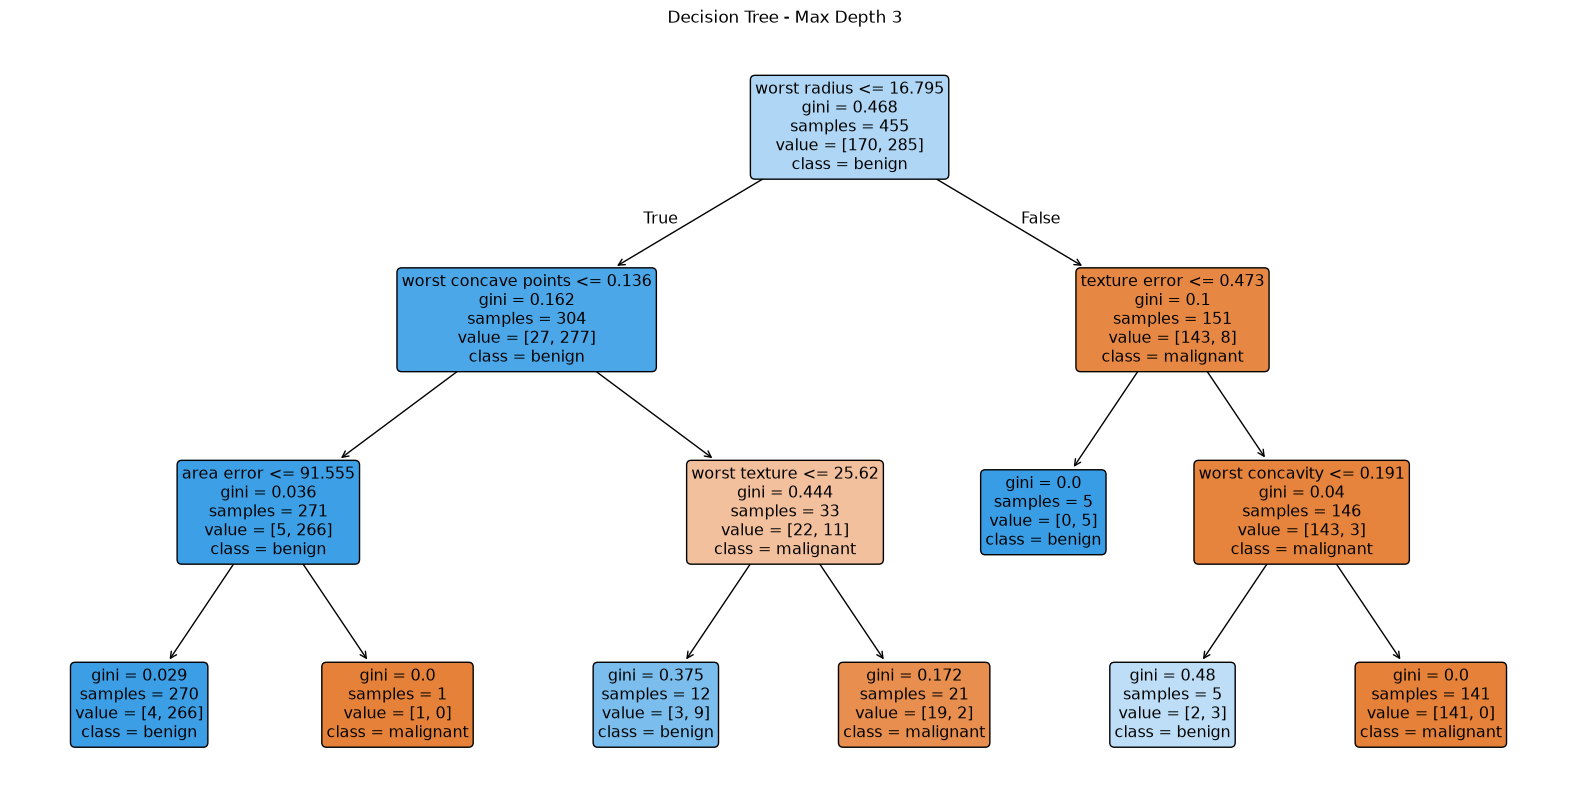

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Load the Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define different tree depths
depths = [1, 3, None]

# Train and evaluate models with different depths
for depth in depths:

    # Create Decision Tree model
    model = DecisionTreeClassifier(
        max_depth=depth,
        criterion="gini",
        random_state=42
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict training and testing data
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate accuracy
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    # Display results
    print(f"\nMax Depth: {depth}")
    print("Train Accuracy:", train_accuracy)
    print("Test Accuracy:", test_accuracy)

# Train a separate model for visualization
visual_model = DecisionTreeClassifier(
    max_depth=3,
    criterion="gini",
    random_state=42
)

visual_model.fit(X_train, y_train)

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    visual_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Max Depth 3")
plt.show()


In [ ]:

# Analysis:

# 1. The model with max_depth=None will generally achieve
#    the highest training accuracy because it can grow deeper
#    and learn more complex patterns from the training data.

# 2. No, the highest training accuracy does not necessarily
#    mean the model is the best.
#    A model may memorize training data and perform poorly
#    on unseen data.

# 3. Increasing tree depth allows the model to learn
#    more complex decision rules.
#    Training accuracy generally increases or stays the same.
#    Test accuracy may improve initially but can decrease
#    when the model starts overfitting.

# 4. The model with max_depth=None may have a higher risk
#    of overfitting because it is allowed to grow without
#    an explicit depth limit.

# 5. max_depth=1 may underfit because the tree is too simple
#    to capture complex patterns.

# 6. max_depth=3 provides a more controlled model,
#    but we must evaluate its performance rather than
#    assume it is always the best choice.

# 7. We should use cross-validation to select
#    a suitable max_depth value.
